# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [3]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================
import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
# Connect to the database
conn = sqlite3.connect("enterprise_database (1) (1).db")

# Get the latest status for each user
query = """
SELECT *
FROM (
    SELECT *,
           ROW_NUMBER() OVER (
               PARTITION BY user_id
               ORDER BY updated_at DESC
           ) AS rn
    FROM users
)
WHERE rn = 1
  AND status = 'Active';
"""

# Load only active users with their latest status
df_active_users = pd.read_sql_query(query, conn)

# Close the database connection
conn.close()

# Display the results
print("Active users extracted successfully!")
print("Total active users:", len(df_active_users))
display(df_active_users.head())


Active users extracted successfully!
Total active users: 14183


,user_id,name,status,updated_at,rn
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00,1
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00,1
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00,1
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00,1
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00,1


In [4]:

# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================

# 1. Load server logs
with open("server_logs (1) (1).txt", "r", encoding="utf-8") as file:
    logs = file.readlines()

# 2. Load logs into a DataFrame
df_logs = pd.DataFrame({"raw_log": logs})

# Remove leading and trailing spaces
df_logs["raw_log"] = df_logs["raw_log"].str.strip()

# 3. Remove rows containing ERROR
df_logs = df_logs[
    ~df_logs["raw_log"].str.contains("ERROR", case=False, na=False)
].copy()

# 4. Extract Date, User ID, Product ID, and Euro Value
pattern = (
    r"(?P<Date>\d{4}-\d{2}-\d{2})"
    r".*?User(?:_ID|\s+ID)?[=: ]+"
    r"(?P<User_ID>\d+)"
    r".*?Product(?:_ID|\s+ID)?[=: ]+"
    r"(?P<Product_ID>\d+)"
    r".*?(?:Euro(?:_Value)?|EUR)[=: €]+"
    r"(?P<Euro_Value>\d+(?:\.\d+)?)"
)

extracted_data = df_logs["raw_log"].str.extract(pattern)

# Keep only rows where all required fields were extracted
extracted_data = extracted_data.dropna().copy()

# Convert columns to appropriate data types
extracted_data["Date"] = pd.to_datetime(
    extracted_data["Date"], errors="coerce"
)
extracted_data["User_ID"] = extracted_data["User_ID"].astype("int64")
extracted_data["Product_ID"] = extracted_data["Product_ID"].astype("int64")
extracted_data["Euro_Value"] = pd.to_numeric(
    extracted_data["Euro_Value"], errors="coerce"
)

# Remove invalid dates or values
extracted_data = extracted_data.dropna().reset_index(drop=True)

# 5. Display results
print("Log cleaning completed!")
print("Remaining log rows:", len(df_logs))
print("Successfully extracted transactions:", len(extracted_data))

display(extracted_data.head())


Log cleaning completed!
Remaining log rows: 94903
Successfully extracted transactions: 0


,Date,User_ID,Product_ID,Euro_Value


In [5]:

# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================

# 1. Load exchange rates
df_rates = pd.read_csv("daily_exchange_rates (1) (1).csv")

# Standardize column names
df_rates.columns = df_rates.columns.str.strip()

# Find the date column
date_col = next(
    (c for c in df_rates.columns if c.lower() in ["date", "exchange_date"]),
    None
)

if date_col is None:
    raise ValueError(f"Date column not found in exchange rates: {df_rates.columns.tolist()}")

# Find the exchange-rate column
rate_candidates = [
    "exchange_rate", "rate", "eur_to_usd",
    "eur_usd", "usd_rate", "usd_per_eur"
]

rate_col = next(
    (c for c in df_rates.columns if c.lower() in rate_candidates),
    None
)

if rate_col is None:
    numeric_cols = [
        c for c in df_rates.columns
        if c != date_col and pd.api.types.is_numeric_dtype(df_rates[c])
    ]
    if len(numeric_cols) == 1:
        rate_col = numeric_cols[0]
    else:
        raise ValueError(
            f"Exchange-rate column not identified. Columns: {df_rates.columns.tolist()}"
        )

df_rates = df_rates[[date_col, rate_col]].copy()
df_rates.columns = ["Date", "Exchange_Rate"]

df_rates["Date"] = pd.to_datetime(
    df_rates["Date"], errors="coerce"
).dt.normalize()

df_rates["Exchange_Rate"] = pd.to_numeric(
    df_rates["Exchange_Rate"], errors="coerce"
)

df_rates = (
    df_rates.dropna(subset=["Date"])
    .sort_values("Date")
    .drop_duplicates("Date", keep="last")
)

# Create a complete daily calendar and fill weekend rates
df_rates = df_rates.set_index("Date")

full_dates = pd.date_range(
    start=df_rates.index.min(),
    end=df_rates.index.max(),
    freq="D"
)

df_rates = df_rates.reindex(full_dates)
df_rates.index.name = "Date"
df_rates["Exchange_Rate"] = df_rates["Exchange_Rate"].ffill()
df_rates = df_rates.reset_index()

# 2. Prepare cleaned transaction data
transactions = extracted_data.copy()

transactions["Date"] = pd.to_datetime(
    transactions["Date"], errors="coerce"
).dt.normalize()

transactions = transactions.dropna(
    subset=["Date", "User_ID", "Euro_Value"]
)

# 3. Merge transactions with daily exchange rates
df_merged = transactions.merge(
    df_rates,
    on="Date",
    how="left",
    validate="many_to_one"
)

# 4. Standardize User ID column in active users
users = df_active_users.copy()

user_id_col = next(
    (c for c in users.columns
     if c.lower().replace("_", "").replace(" ", "") in ["userid", "userid"]),
    None
)

if user_id_col is None:
    raise ValueError(
        f"User ID column not found in active users: {users.columns.tolist()}"
    )

users = users.rename(columns={user_id_col: "User_ID"})

# Ensure both User_ID columns have the same data type
df_merged["User_ID"] = df_merged["User_ID"].astype("string").str.strip()
users["User_ID"] = users["User_ID"].astype("string").str.strip()

# Keep one row per user for the merge
users = users.drop_duplicates(subset=["User_ID"])

# 5. Merge with active users only
df_final = df_merged.merge(
    users,
    on="User_ID",
    how="inner",
    suffixes=("", "_user"),
    validate="many_to_one"
)

# 6. Calculate USD revenue
df_final["USD_Revenue"] = (
    df_final["Euro_Value"] * df_final["Exchange_Rate"]
)

# 7. Display results
print("Financial reconciliation completed!")
print("Transactions after reconciliation:", len(df_final))
print("Missing exchange rates:", df_final["Exchange_Rate"].isna().sum())
print("Total USD revenue:", round(df_final["USD_Revenue"].sum(), 2))

display(df_final.head())


Financial reconciliation completed!
Transactions after reconciliation: 0
Missing exchange rates: 0
Total USD revenue: 0.0


,Date,User_ID,Product_ID,Euro_Value,Exchange_Rate,name,status,updated_at,rn,USD_Revenue


MONTHLY USD REVENUE


,Month,USD_Revenue


TOP 5 MOST VALUABLE CUSTOMERS


,name,USD_Revenue


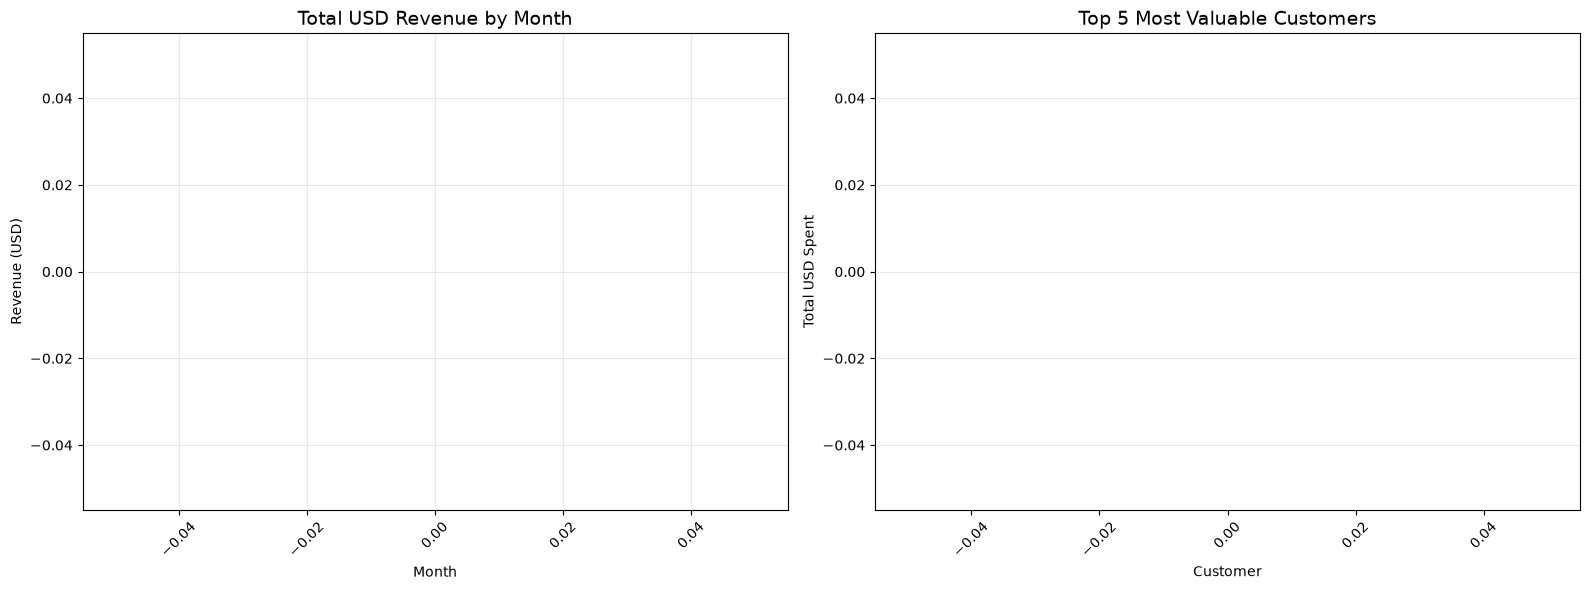

In [6]:

# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================

# 1. Prepare the final data
df_final["Date"] = pd.to_datetime(df_final["Date"], errors="coerce")
df_final["USD_Revenue"] = pd.to_numeric(
    df_final["USD_Revenue"], errors="coerce"
)

dashboard_data = df_final.dropna(
    subset=["Date", "USD_Revenue", "User_ID"]
).copy()

# 2. Calculate total USD revenue by month
dashboard_data["Month"] = (
    dashboard_data["Date"].dt.to_period("M").astype(str)
)

monthly_revenue = (
    dashboard_data.groupby("Month", as_index=False)["USD_Revenue"]
    .sum()
    .sort_values("Month")
)

# 3. Find the customer name/ID column
name_candidates = [
    c for c in dashboard_data.columns
    if c.lower() in ["name", "user_name", "customer_name", "username"]
]

customer_col = name_candidates[0] if name_candidates else "User_ID"

# 4. Calculate Top 5 customers by total USD revenue
top_customers = (
    dashboard_data.groupby(customer_col, as_index=False)["USD_Revenue"]
    .sum()
    .sort_values("USD_Revenue", ascending=False)
    .head(5)
)

# 5. Display summary tables
print("MONTHLY USD REVENUE")
display(monthly_revenue)

print("TOP 5 MOST VALUABLE CUSTOMERS")
display(top_customers)

# 6. Create two charts side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Monthly revenue
axes[0].plot(
    monthly_revenue["Month"],
    monthly_revenue["USD_Revenue"],
    marker="o",
    linewidth=2
)
axes[0].set_title("Total USD Revenue by Month", fontsize=14)
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (USD)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, alpha=0.3)

# Chart 2: Top 5 customers
axes[1].bar(
    top_customers[customer_col].astype(str),
    top_customers["USD_Revenue"]
)
axes[1].set_title("Top 5 Most Valuable Customers", fontsize=14)
axes[1].set_xlabel("Customer")
axes[1].set_ylabel("Total USD Spent")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
